In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# loading the datsets 

In [2]:
df = pd.read_excel('../data/processed/../data/processed/Final_EMR_analysis_data.xlsx')
df.head()

,age group,sex,education,profession,department,db_version,hprs_topic,hprs_provider,emr_designated_computer,emr_online_offline,...,tediousness_emr_data_collection,meaningful_data_collection,data_collection_burden,data_collection_monitoring,data_collection_appreciation,org_factor_organizational_rules,org_factor_financial_resources,org_factor_organizational_practices,org_factor_inadequate_human_resources,org_factor_poor_leadership
0,51-60,1,Postgraduate,Doctor,Specialist Clinic,Other,Other,Other,1,2,...,2,2,2,4,2,1,1,1,0,0
1,19-30,1,Diploma,Records Officer,Specialist Clinic,Global Care V.10.1,Data Analysis,Unit/Department head,1,2,...,1,5,1,4,5,1,1,1,0,0
2,31-40,1,Degree,Records Officer,Records,Global Care V.10.1,Other,Other,1,2,...,1,5,2,1,5,1,0,1,1,0
3,19-30,1,Diploma,Records Officer,Records,Other,Data Analysis,Unit/Department head,1,2,...,1,5,1,4,5,1,0,0,1,0
4,31-40,1,Degree,Nurse,Family Planning,Other,Other,EHIS focal person,1,1,...,1,5,1,1,5,1,0,0,1,0


In [3]:
df.columns

Index(['age group', 'sex', 'education', 'profession', 'department',
       'db_version', 'hprs_topic', 'hprs_provider', 'emr_designated_computer',
       'emr_online_offline', 'network_connectivity_challenge',
       'alternative_power_outage', 'designated_person_patient_data',
       'patient_registration_method', 'designated_person_ehis_reports',
       'orientation_emr_utilization', 'hprs_training_last_12_months',
       'emr_software_rating', 'technical_support_time', 'likely_to_use_emr',
       'emr_is_complex', 'need_technical_support',
       'good_system_functions_integration', 'confidence_using_system',
       'used_emr_decision_making', 'capacity_decision_making',
       'regular_monitoring_evaluation_supervision',
       'health_information_policies', 'action_plan_emr',
       'regular_meetings_emr_utilization', 'regular_feedback_report',
       'emr_performance_monitoring', 'timely_completion_emr_tasks',
       'commitment_emr_mission', 'tediousness_emr_data_collection',
  

In [4]:
# standarsizing the column names:
def clean_column_names(df):
    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
        .str.replace(r'[\s/]+', '_', regex=True)  # spaces and slashes → _
        .str.replace(r'[^\w]', '', regex=True)    # remove non-word chars
    )
    return df
df = clean_column_names(df)

In [5]:
df.columns

Index(['age_group', 'sex', 'education', 'profession', 'department',
       'db_version', 'hprs_topic', 'hprs_provider', 'emr_designated_computer',
       'emr_online_offline', 'network_connectivity_challenge',
       'alternative_power_outage', 'designated_person_patient_data',
       'patient_registration_method', 'designated_person_ehis_reports',
       'orientation_emr_utilization', 'hprs_training_last_12_months',
       'emr_software_rating', 'technical_support_time', 'likely_to_use_emr',
       'emr_is_complex', 'need_technical_support',
       'good_system_functions_integration', 'confidence_using_system',
       'used_emr_decision_making', 'capacity_decision_making',
       'regular_monitoring_evaluation_supervision',
       'health_information_policies', 'action_plan_emr',
       'regular_meetings_emr_utilization', 'regular_feedback_report',
       'emr_performance_monitoring', 'timely_completion_emr_tasks',
       'commitment_emr_mission', 'tediousness_emr_data_collection',
  

In [6]:
df.iloc[:50:, :20]

,age_group,sex,education,profession,department,db_version,hprs_topic,hprs_provider,emr_designated_computer,emr_online_offline,network_connectivity_challenge,alternative_power_outage,designated_person_patient_data,patient_registration_method,designated_person_ehis_reports,orientation_emr_utilization,hprs_training_last_12_months,emr_software_rating,technical_support_time,likely_to_use_emr
0,51-60,1,Postgraduate,Doctor,Specialist Clinic,Other,Other,Other,1,2,2,Manual paper register,1,Both,1,1,0,2,Within 24 hours,4
1,19-30,1,Diploma,Records Officer,Specialist Clinic,Global Care V.10.1,Data Analysis,Unit/Department head,1,2,3,Manual paper register,1,EHIS,1,1,1,1,Within 24 hours,1
2,31-40,1,Degree,Records Officer,Records,Global Care V.10.1,Other,Other,1,2,2,UPS,1,EHIS,1,1,0,1,Within 24 hours,5
3,19-30,1,Diploma,Records Officer,Records,Other,Data Analysis,Unit/Department head,1,2,2,Manual paper register,1,Paper-based registration,1,1,1,1,Within 24 hours,5
4,31-40,1,Degree,Nurse,Family Planning,Other,Other,EHIS focal person,1,1,2,Manual paper register,1,EHIS,1,1,0,1,Within 24 hours,5
5,31-40,1,Degree,Nurse,Specialist Clinic,Other,NaN,Other,1,2,2,Manual paper register,1,EHIS,1,1,0,1,Within 24 hours,5
6,41-50,1,Postgraduate,Records Officer,Specialist Clinic,Other,Data Entry,EHIS focal person,1,2,2,Generator,1,EHIS,1,1,1,1,Within 24 hours,5
7,31-40,0,Degree,Other,Records,Global Care V.10.1,Other,Other,1,2,2,Generator,1,EHIS,1,1,0,1,Within 24 hours,5
8,31-40,1,Diploma,Nurse,Other,Other,Data Entry,EHIS focal person,1,2,2,Generator,1,Both,1,0,1,1,Within 24 hours,5
9,41-50,1,Postgraduate,Account Officer,Specialist Clinic,Other,Other,Other,1,2,2,Generator,1,Paper-based registration,1,1,0,1,Within 24 hours,5


# the total records

In [7]:
df.shape

(154, 44)

In [8]:
df.isnull().sum()

age_group                                     0
sex                                           0
education                                     0
profession                                    0
department                                    0
db_version                                    0
hprs_topic                                   66
hprs_provider                                64
emr_designated_computer                       0
emr_online_offline                            0
network_connectivity_challenge                0
alternative_power_outage                      0
designated_person_patient_data                0
patient_registration_method                   0
designated_person_ehis_reports                0
orientation_emr_utilization                   0
hprs_training_last_12_months                  0
emr_software_rating                           0
technical_support_time                        0
likely_to_use_emr                             0
emr_is_complex                          

In [9]:
# preview on age_group
df['age_group'].value_counts()

age_group
19-30    55
41-50    37
31-40    35
51-60    25
<19       2
Name: count, dtype: int64

# Age group preview

In [10]:
df['age_group'].isnull().sum()

0

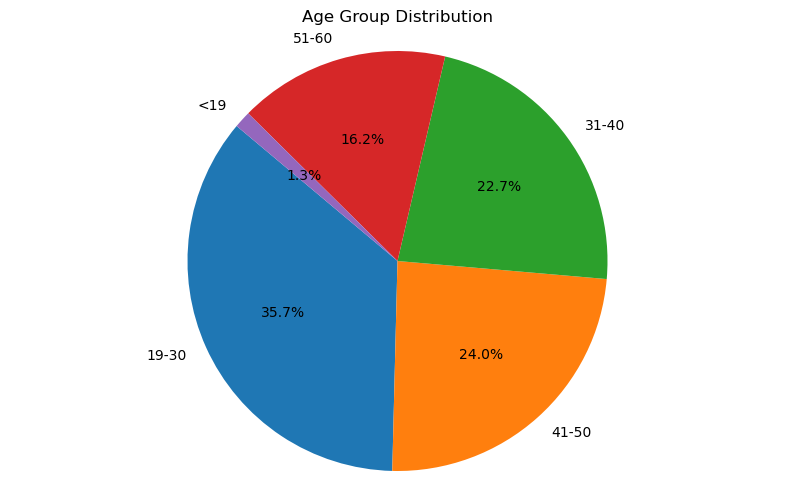

<Figure size 640x480 with 0 Axes>

In [11]:
plt.figure(figsize=(10, 6))
plt.pie(df['age_group'].value_counts(), labels=df['age_group'].value_counts().index, autopct='%1.1f%%', startangle=140)
plt.title('Age Group Distribution')
plt.axis('equal')
plt.show()
plt.savefig('../reports/figures/demographics/age.png')

# Profession preview

In [12]:
# preview of population
df['profession'].value_counts()

profession
Doctor                    53
Nurse                     52
Records Officer           24
Account Officer            7
Data Capturer              7
Other                      6
Administrative Officer     5
Name: count, dtype: int64

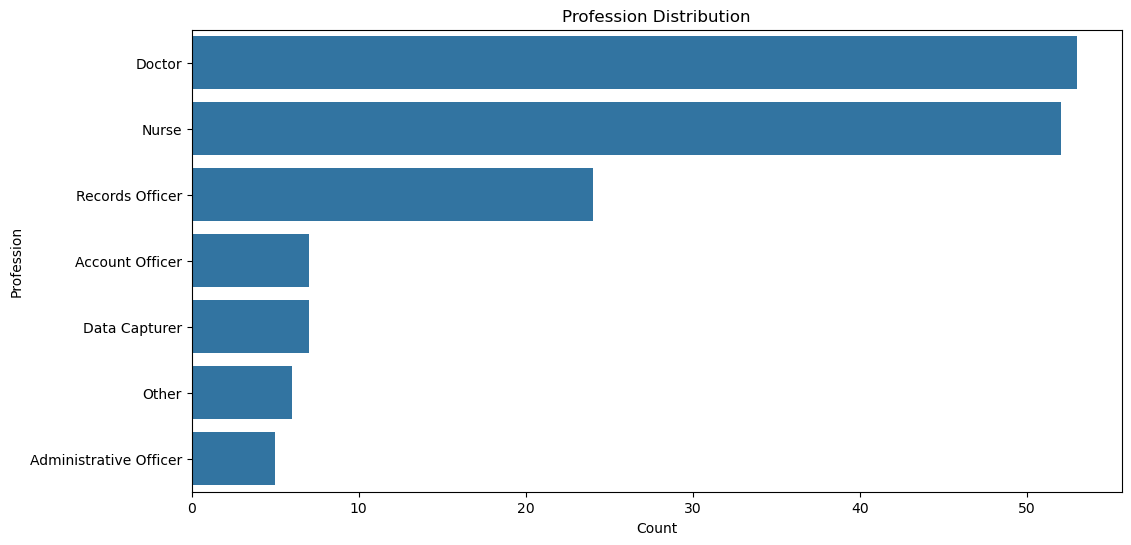

<Figure size 640x480 with 0 Axes>

In [13]:
plt.figure(figsize=(12, 6))
sns.countplot(y='profession', data=df, order=df['profession'].value_counts().index)
plt.title('Profession Distribution')
plt.xlabel('Count')
plt.ylabel('Profession')
plt.show()
plt.savefig('../reports/figures/demographics/profession_distiution.png')
# preview on marital_status

# Gender distribution

In [14]:
df['sex'].value_counts()

sex
1    107
0     47
Name: count, dtype: int64

In [15]:
# where, 1 -->  Fermale
# 0 --> male

gender_mapping = {
    1: 'Female',
    0: 'Males'
}

df['sex'].map(gender_mapping).value_counts()


sex
Female    107
Males      47
Name: count, dtype: int64

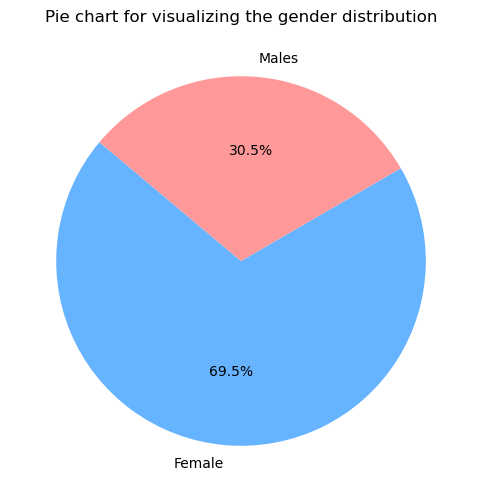

<Figure size 640x480 with 0 Axes>

In [16]:
# plotting the visualization for the gender:

plt.figure(figsize=(12, 6))
plt.pie(df['sex'].map(gender_mapping).value_counts(), labels=df['sex'].map(gender_mapping).value_counts().index, autopct='%1.1f%%', startangle=140, colors=['#66b3ff','#ff9999'])
plt.title('Pie chart for visualizing the gender distribution')
plt.show()
plt.savefig('../reports/figures/demographics/gender.png')

# Previewing the Education distribution

In [17]:
df['education'].value_counts()

education
Degree                    87
Postgraduate              24
Diploma                   17
Postgraduate              13
Diploma                   11
Postgraduate  | Degree     1
Matric                     1
Name: count, dtype: int64

In [18]:
df['education'].unique()

array(['Postgraduate ', 'Diploma ', 'Degree', 'Postgraduate  | Degree',
       'Postgraduate', 'Diploma', 'Matric'], dtype=object)

In [19]:
mapping_education = {
    'Postgraduate ': 'Postgraduate',
    'Diploma ': 'Diploma',
    'Degree': 'Degree',
    'Postgraduate  | Degree': 'Degree',
    'Postgraduate': 'Postgraduate', 
    'Diploma': 'Diploma',
    'Matric': 'Matric',
}
df['education'] = df['education'].replace(mapping_education)

In [20]:
df['education'].value_counts()

education
Degree          88
Postgraduate    37
Diploma         28
Matric           1
Name: count, dtype: int64

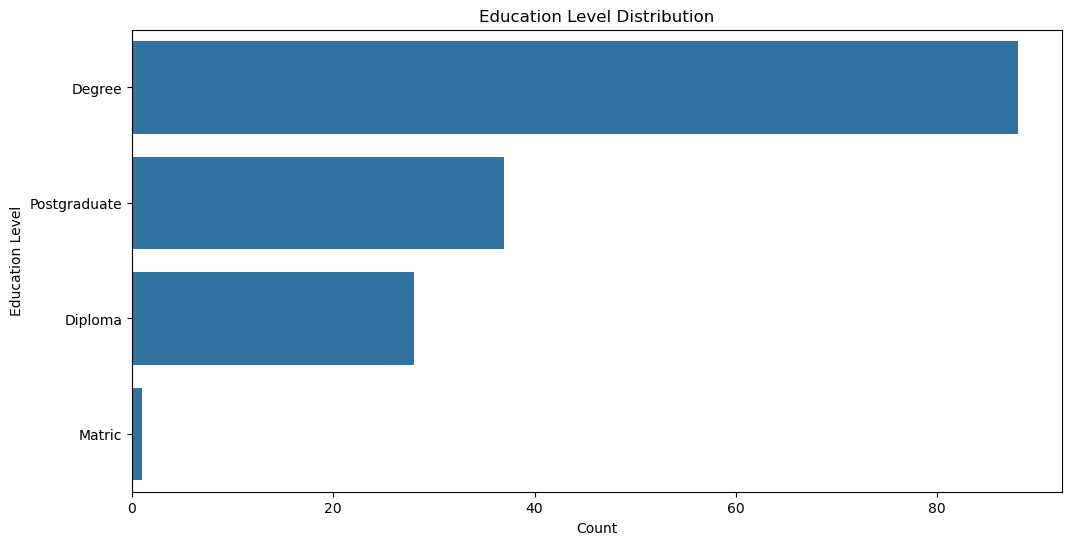

<Figure size 640x480 with 0 Axes>

In [21]:
plt.figure(figsize=(12, 6))
sns.countplot(y='education', data=df, order=df['education'].value_counts().index)
plt.title('Education Level Distribution')
plt.xlabel('Count')
plt.ylabel('Education Level')
plt.show()
plt.savefig('../reports/figures/demographics/education_level.png')
# preview on marital_status

# Previewing respondents opinions about EMR complexity

In [22]:
df['emr_is_complex'].value_counts()

emr_is_complex
1    59
2    59
3    16
4    13
5     7
Name: count, dtype: int64

In [23]:
emr_complex_mapping = {
    1: 'Strogly Disagree',
    2: 'Disagree',
    3: 'Neutral',
    4: 'Agree',
    5: 'Strongly Agree'
}

df['emr_is_complex'] = df['emr_is_complex'].map(emr_complex_mapping)

In [24]:
df['emr_is_complex'].value_counts()

emr_is_complex
Strogly Disagree    59
Disagree            59
Neutral             16
Agree               13
Strongly Agree       7
Name: count, dtype: int64

/var/folders/rr/bq788s793lj_d9_kkdn7gqrr0000gn/T/ipykernel_3583/3992682837.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='emr_is_complex', data=df, order=df['emr_is_complex'].value_counts().index, palette='viridis')


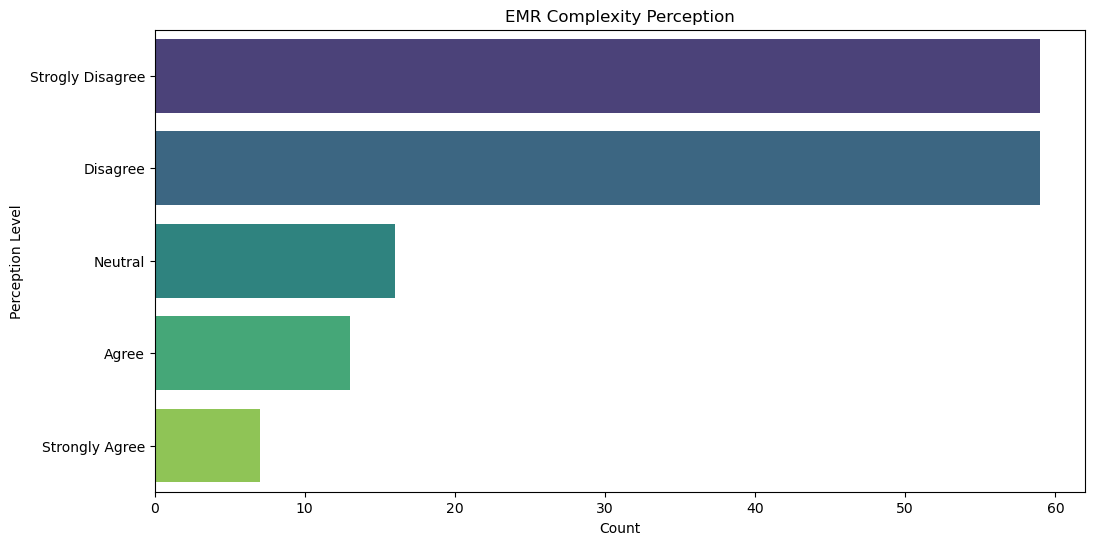

<Figure size 640x480 with 0 Axes>

In [25]:
# visulaizing the data
plt.figure(figsize=(12, 6))
sns.countplot(y='emr_is_complex', data=df, order=df['emr_is_complex'].value_counts().index, palette='viridis')
plt.title('EMR Complexity Perception')
plt.xlabel('Count')
plt.ylabel('Perception Level')
plt.show()
plt.savefig('../reports/figures/technical_complexity/emr_complexity_perception.png')

In [26]:
df['sex'] = df['sex'].replace(gender_mapping)

## Gender and emr complexity correlation 

In [27]:
gender_emr_complexity_group = df.groupby('sex')['emr_is_complex'].value_counts().unstack().fillna(0)
gender_emr_complexity_group

emr_is_complex,Agree,Disagree,Neutral,Strogly Disagree,Strongly Agree
sex,,,,,
Female,9,39,10,45,4
Males,4,20,6,14,3


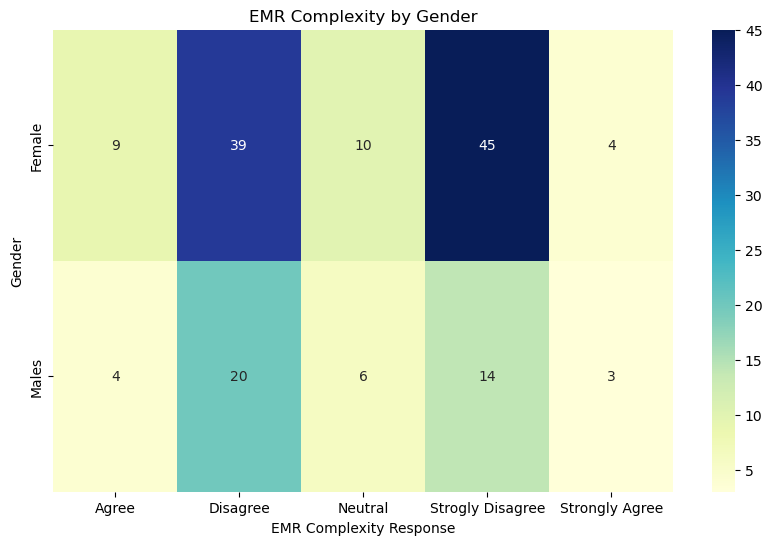

In [28]:
plt.figure(figsize=(10, 6))
sns.heatmap(gender_emr_complexity_group, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("EMR Complexity by Gender")
plt.ylabel("Gender")
plt.xlabel("EMR Complexity Response")
plt.show()

# previewing the profession relation to emr complexity

In [29]:
profession_emr_complexity_group = df.groupby('profession')['emr_is_complex'].value_counts().unstack().fillna(0)
profession_emr_complexity_group


emr_is_complex,Agree,Disagree,Neutral,Strogly Disagree,Strongly Agree
profession,,,,,
Account Officer,2.0,1.0,1.0,3.0,0.0
Administrative Officer,0.0,2.0,1.0,2.0,0.0
Data Capturer,4.0,2.0,0.0,1.0,0.0
Doctor,3.0,25.0,5.0,19.0,1.0
Nurse,3.0,20.0,4.0,21.0,4.0
Other,0.0,3.0,0.0,2.0,1.0
Records Officer,1.0,6.0,5.0,11.0,1.0


In [30]:
profession_emr_complexity_group = profession_emr_complexity_group[['Strogly Disagree', 'Disagree', 'Neutral', 'Agree', 'Strongly Agree']]

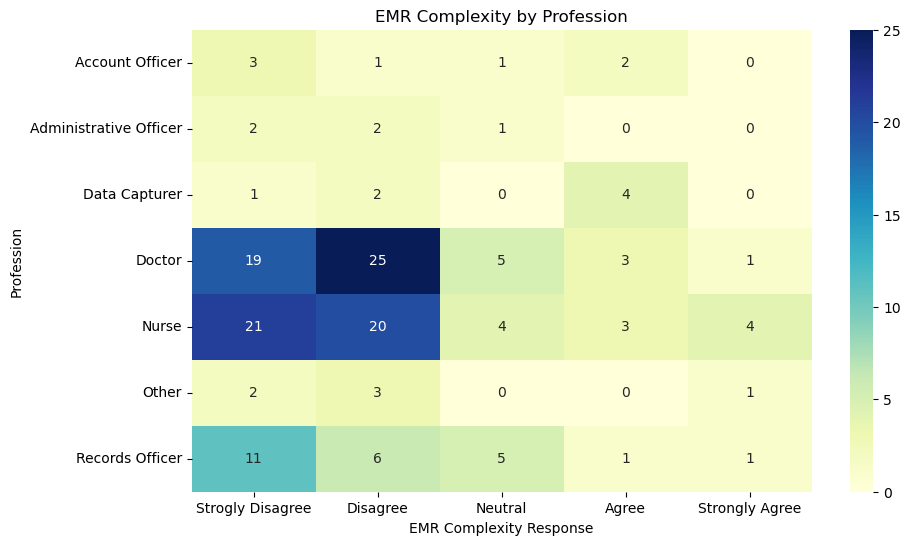

<Figure size 640x480 with 0 Axes>

In [31]:
plt.figure(figsize=(10, 6))
sns.heatmap(profession_emr_complexity_group, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("EMR Complexity by Profession")
plt.ylabel("Profession")
plt.xlabel("EMR Complexity Response")
plt.show()
plt.savefig('../reports/figures/technical_complexity/profession_.emr_complexity.png')

# HPRS training distrbution

In [32]:
df['hprs_training_last_12_months'].value_counts()

hprs_training_last_12_months
0               117
1                34
1 | 0             1
Option 3 | 1      1
0 | Option 3      1
Name: count, dtype: int64

In [33]:
df['hprs_training_last_12_months'].unique()

array([0, 1, '1 | 0', 'Option 3 | 1', '0 | Option 3'], dtype=object)

In [34]:
hprs_training_mapping = {
    1: 'Yes',
    0: 'No',
    '1 | 0': 'Yes',
    'Option 3 | 1': 'Yes',
    '0 | Option 3': 'No'
}
df['hprs_training_last_12_months'] = df['hprs_training_last_12_months'].replace(hprs_training_mapping)
df['hprs_training_last_12_months'].value_counts()

hprs_training_last_12_months
No     118
Yes     36
Name: count, dtype: int64

In [35]:
hprs_training_emr_complexity_group = df.groupby('hprs_training_last_12_months')['emr_is_complex'].value_counts().unstack().fillna(0)
hprs_training_emr_complexity_group

emr_is_complex,Agree,Disagree,Neutral,Strogly Disagree,Strongly Agree
hprs_training_last_12_months,,,,,
No,13.0,41.0,13.0,45.0,6.0
Yes,0.0,18.0,3.0,14.0,1.0


In [36]:
hprs_training_emr_complexity_group = hprs_training_emr_complexity_group[['Strogly Disagree', 'Disagree', 'Neutral', 'Agree', 'Strongly Agree']]

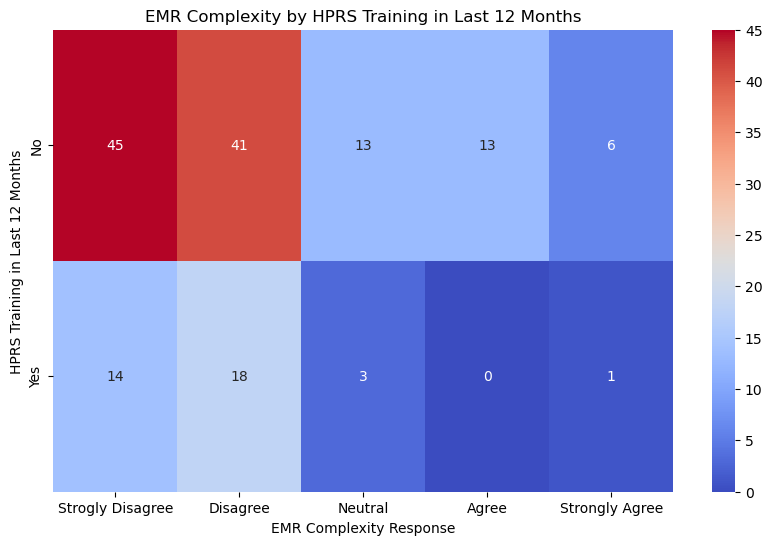

In [37]:
plt.figure(figsize=(10, 6))
sns.heatmap(hprs_training_emr_complexity_group, annot=True, fmt=".0f", cmap="coolwarm")
plt.title("EMR Complexity by HPRS Training in Last 12 Months")
plt.xlabel("EMR Complexity Response")
plt.ylabel("HPRS Training in Last 12 Months")
plt.show()

In [38]:
hprs_training_emr_complexity_group.describe()

emr_is_complex,Strogly Disagree,Disagree,Neutral,Agree,Strongly Agree
count,2.00000,2.000000,2.000000,2.000000,2.000000
mean,29.50000,29.500000,8.000000,6.500000,3.500000
std,21.92031,16.263456,7.071068,9.192388,3.535534
min,14.00000,18.000000,3.000000,0.000000,1.000000
25%,21.75000,23.750000,5.500000,3.250000,2.250000
50%,29.50000,29.500000,8.000000,6.500000,3.500000
75%,37.25000,35.250000,10.500000,9.750000,4.750000
max,45.00000,41.000000,13.000000,13.000000,6.000000


In [39]:
hprs_training_emr_complexity_group.mean()

emr_is_complex
Strogly Disagree    29.5
Disagree            29.5
Neutral              8.0
Agree                6.5
Strongly Agree       3.5
dtype: float64

# Technical Component analysis

## Technical performance overview

###  Emr software rating

In [40]:
df['emr_software_rating'].value_counts()

emr_software_rating
1    106
2     46
3      2
Name: count, dtype: int64

In [41]:
emr_complex_mapping = {
    1: 'Easy',
    2: 'Moderate',
    3: 'Difficult',
}
df['emr_software_rating'] = df['emr_software_rating'].replace(emr_complex_mapping)
df['emr_software_rating'].value_counts()

emr_software_rating
Easy         106
Moderate      46
Difficult      2
Name: count, dtype: int64

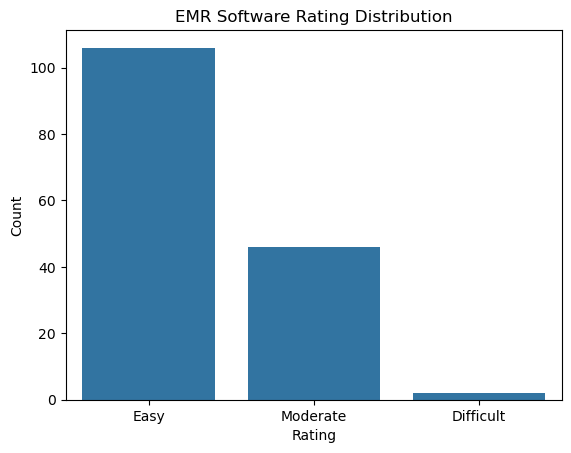

In [42]:
sns.barplot(x=df['emr_software_rating'].value_counts().index, y=df['emr_software_rating'].value_counts().values)
plt.title('EMR Software Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

### Emr_complex to use

In [43]:
df['emr_is_complex'].value_counts()

emr_is_complex
Strogly Disagree    59
Disagree            59
Neutral             16
Agree               13
Strongly Agree       7
Name: count, dtype: int64

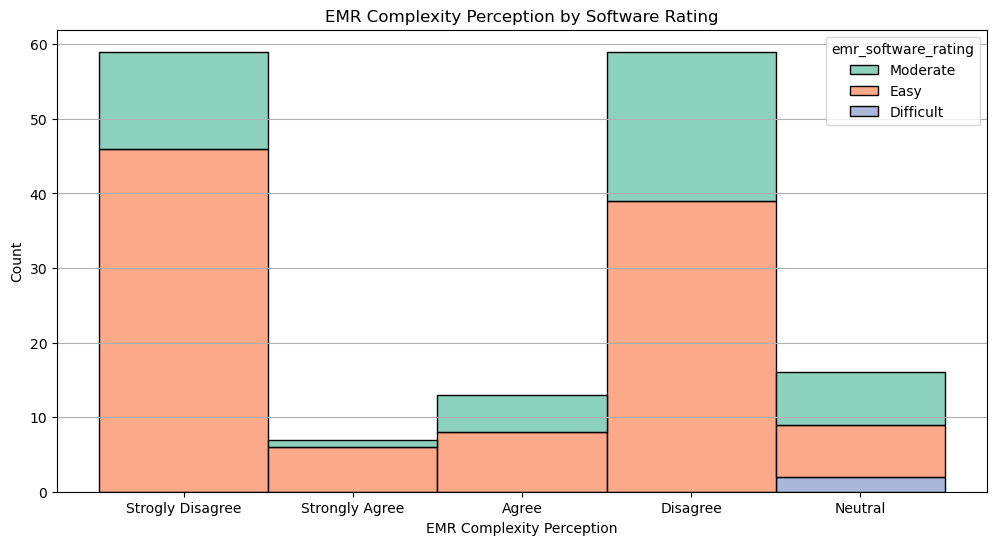

In [44]:
plt.figure(figsize=(12, 6))
sns.histplot(data=df, x='emr_is_complex', hue='emr_software_rating', multiple='stack', palette='Set2')
plt.title('EMR Complexity Perception by Software Rating')   
plt.xlabel('EMR Complexity Perception')
plt.ylabel('Count')
plt.grid(axis='y')
plt.show()

In [45]:
df['timely_completion_emr_tasks'].value_counts()

timely_completion_emr_tasks
4           68
3           40
5           25
2           14
1            6
0 Answer     1
Name: count, dtype: int64

### timely completion of emr tasks


In [46]:
df['timely_completion_emr_tasks'].unique()

array([3, 5, 4, 1, 2, '0 Answer'], dtype=object)

In [47]:
timely_completion_mapping = {
    1: 'Strongly Disagree',
    2: 'Disagree',
    3: 'Neutral',
    4: 'Agree',
    5: 'Strongly Agree',
    '0 Answer': 'Neutral'
}
df['timely_completion_emr_tasks'] = df['timely_completion_emr_tasks'].replace(timely_completion_mapping)
df['timely_completion_emr_tasks'].value_counts()

timely_completion_emr_tasks
Agree                68
Neutral              41
Strongly Agree       25
Disagree             14
Strongly Disagree     6
Name: count, dtype: int64

In [48]:
# timely completion of tasks with complex EMR systems

complex_timely_completion_group = df.groupby('emr_is_complex')['timely_completion_emr_tasks'].value_counts().unstack().fillna(0)
complex_timely_completion_group = complex_timely_completion_group[['Strongly Disagree', 'Disagree', 'Neutral', 'Agree', 'Strongly Agree']]
complex_timely_completion_group

timely_completion_emr_tasks,Strongly Disagree,Disagree,Neutral,Agree,Strongly Agree
emr_is_complex,,,,,
Agree,0.0,1.0,9.0,2.0,1.0
Disagree,2.0,10.0,10.0,30.0,7.0
Neutral,1.0,1.0,8.0,5.0,1.0
Strogly Disagree,1.0,2.0,14.0,27.0,15.0
Strongly Agree,2.0,0.0,0.0,4.0,1.0


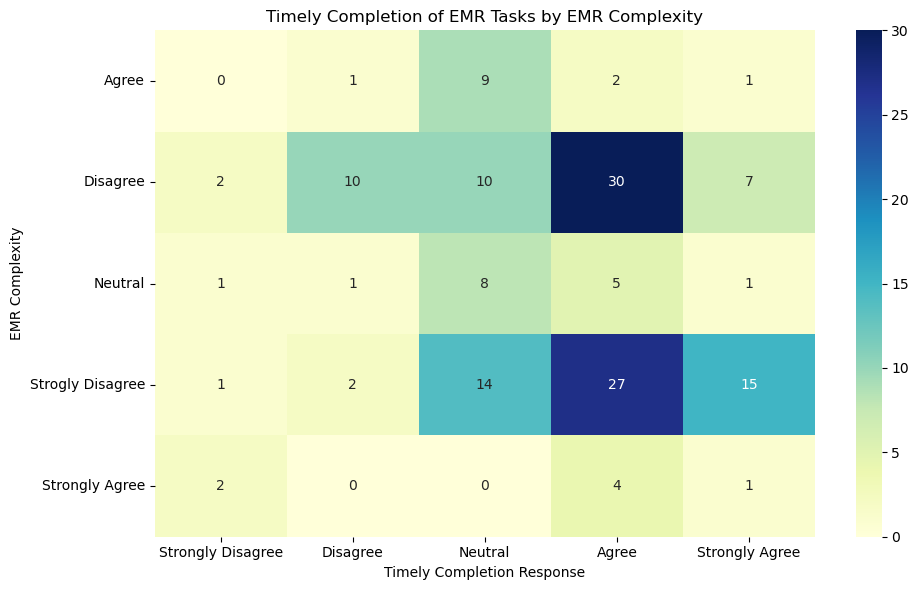

In [49]:
plt.figure(figsize=(10, 6))
sns.heatmap(complex_timely_completion_group, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Timely Completion of EMR Tasks by EMR Complexity")
plt.ylabel("EMR Complexity")
plt.xlabel("Timely Completion Response")
plt.tight_layout()
plt.show()

### good system function integration

In [50]:
df['good_system_functions_integration'].value_counts()

good_system_functions_integration
4    84
5    29
3    24
2    10
1     7
Name: count, dtype: int64

In [51]:
system_functions_mapping = {
    1: 'Strongly Disagree',
    2: 'Disagree',
    3: 'Neutral',
    4: 'Agree',
    5: 'Strongly Agree',
}
df['good_system_functions_integration'] = df['good_system_functions_integration'].replace(system_functions_mapping)
df['good_system_functions_integration'].value_counts()

good_system_functions_integration
Agree                84
Strongly Agree       29
Neutral              24
Disagree             10
Strongly Disagree     7
Name: count, dtype: int64

/var/folders/rr/bq788s793lj_d9_kkdn7gqrr0000gn/T/ipykernel_3583/2713818640.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='good_system_functions_integration', data=df, order=df['good_system_functions_integration'].value_counts().index, palette='magma')


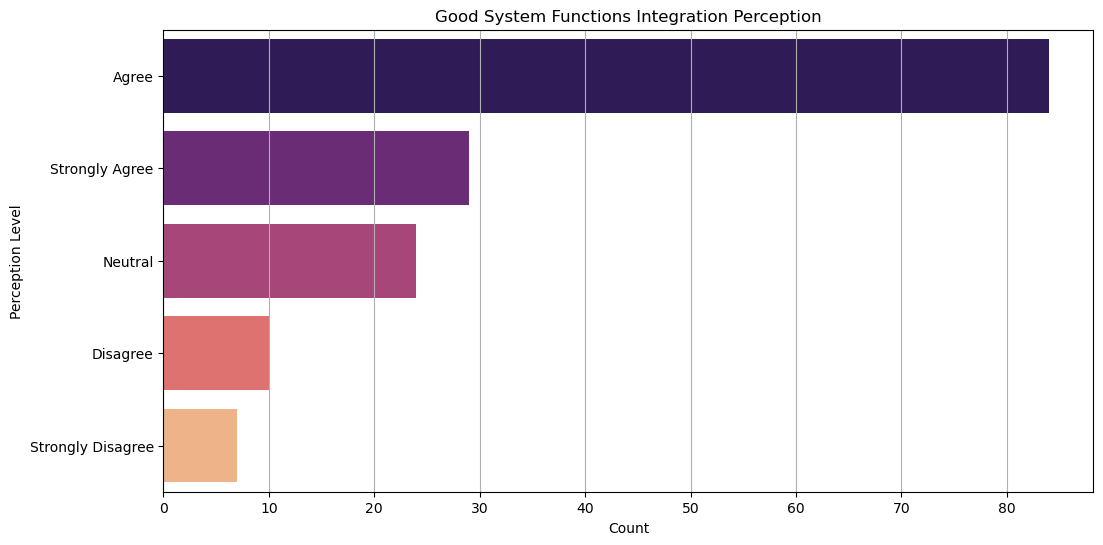

In [52]:
plt.figure(figsize=(12, 6))
sns.countplot(y='good_system_functions_integration', data=df, order=df['good_system_functions_integration'].value_counts().index, palette='magma')
plt.title('Good System Functions Integration Perception')
plt.xlabel('Count')                                                                                                                                  
plt.ylabel('Perception Level')
plt.grid(axis='x')
plt.show()

##  Infrastructure Challenge assessment

### Network connectivity infrastructure

In [53]:
df['network_connectivity_challenge'].value_counts()

network_connectivity_challenge
2    116
3     29
4      7
1      2
Name: count, dtype: int64

In [54]:
network_connectivity_mapping = {
    1: 'Never',
    2: 'Sometimes',
    3: 'Most times',
    4: 'Always'
}
df['network_connectivity_challenge'] = df['network_connectivity_challenge'].replace(network_connectivity_mapping)
df['network_connectivity_challenge'].value_counts()

network_connectivity_challenge
Sometimes     116
Most times     29
Always          7
Never           2
Name: count, dtype: int64

In [55]:
dept_network_group = df.groupby('department')['network_connectivity_challenge'].value_counts().unstack().fillna(0)
dept_network_group = dept_network_group[['Never', 'Sometimes', 'Most times', 'Always']]
dept_network_group

network_connectivity_challenge,Never,Sometimes,Most times,Always
department,,,,
Accident and Emergency,0.0,1.0,0.0,0.0
Billing,0.0,2.0,1.0,0.0
Dental,0.0,6.0,1.0,0.0
Family Planning,0.0,2.0,2.0,1.0
Maternity,0.0,5.0,0.0,0.0
Ophthalmology,0.0,4.0,0.0,0.0
Other,0.0,36.0,11.0,6.0
Records,0.0,14.0,1.0,0.0
Specialist Clinic,2.0,46.0,13.0,0.0


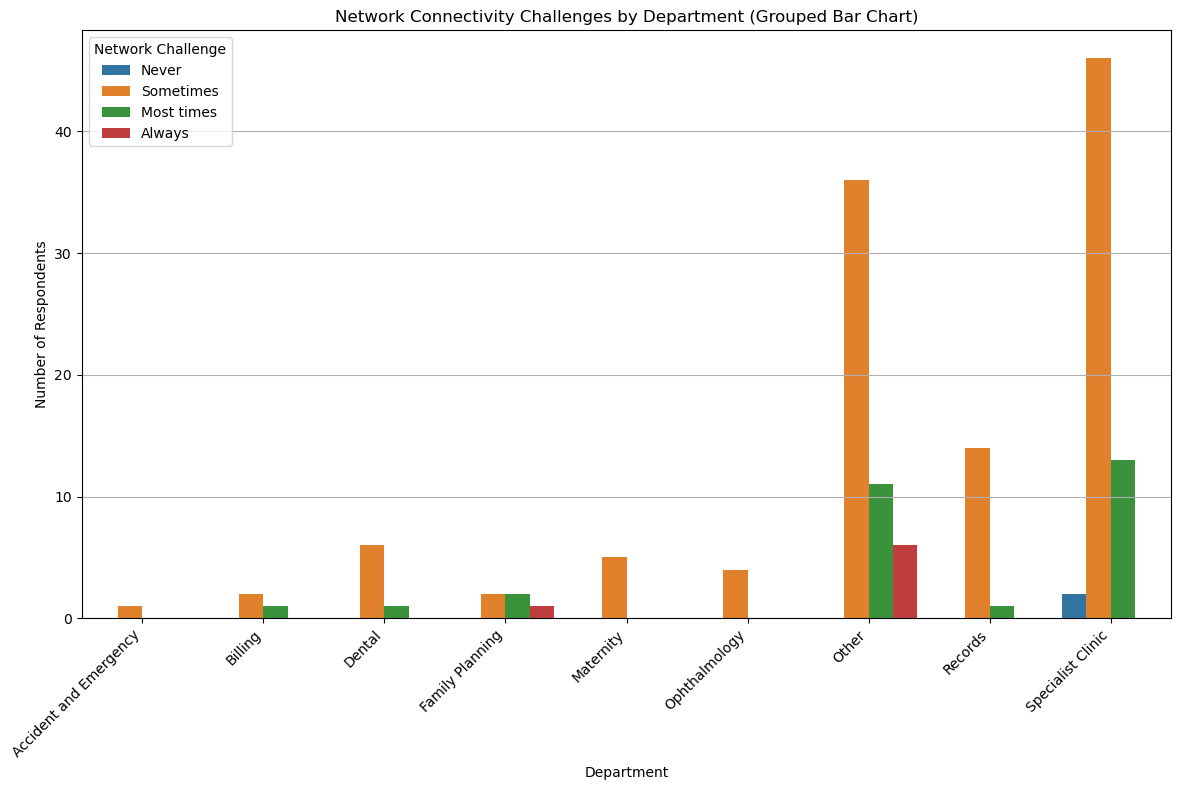

In [56]:
dept_network_group_melted = dept_network_group.reset_index().melt(id_vars='department', var_name='Network Challenge', value_name='Count')
plt.figure(figsize=(12, 8))
sns.barplot(data=dept_network_group_melted, x='department', y='Count', hue='Network Challenge')
plt.title('Network Connectivity Challenges by Department (Grouped Bar Chart)')
plt.xlabel('Department')
plt.ylabel('Number of Respondents')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

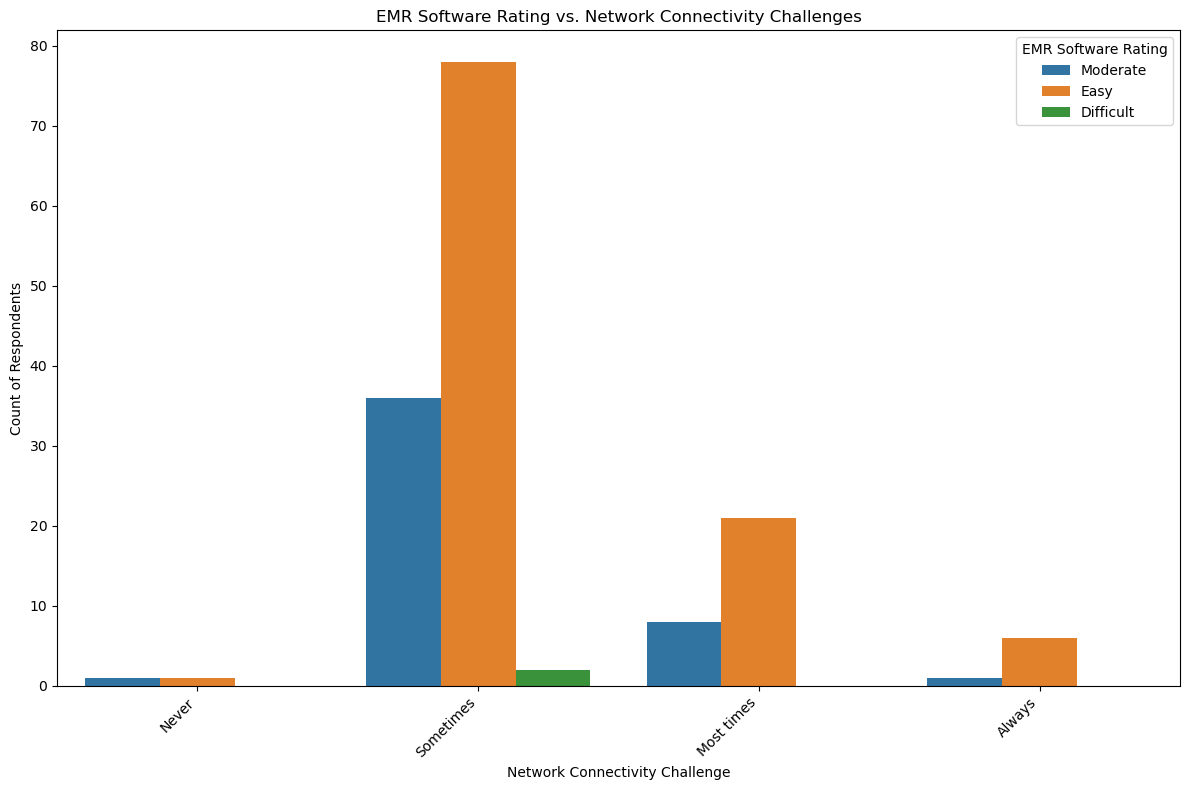

In [57]:
network_order = ['Never', 'Sometimes', 'Most times', 'Always']
plt.figure(figsize=(12, 8))
sns.countplot(
    data=df,
    x='network_connectivity_challenge',
    hue='emr_software_rating',
    order=network_order
)

# Add clear labels and a title
plt.title('EMR Software Rating vs. Network Connectivity Challenges')
plt.xlabel('Network Connectivity Challenge')
plt.ylabel('Count of Respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='EMR Software Rating')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

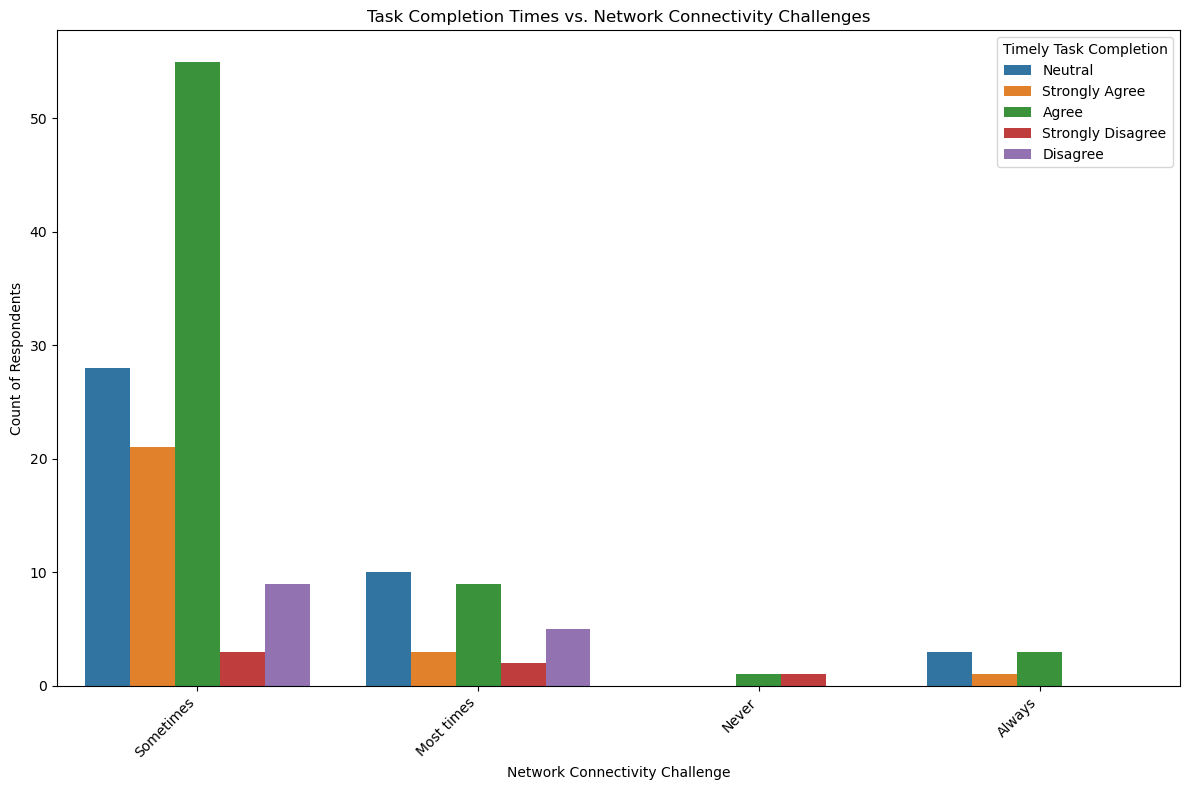

In [58]:
tasks_order = ['No', 'Most of the time', 'Yes']

# Create the grouped bar chart using seaborn.countplot()
plt.figure(figsize=(12, 8))
sns.countplot(
    data=df,
    x='network_connectivity_challenge',
    hue='timely_completion_emr_tasks',

)

# Add clear labels and a title
plt.title('Task Completion Times vs. Network Connectivity Challenges')
plt.xlabel('Network Connectivity Challenge')
plt.ylabel('Count of Respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Timely Task Completion')

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

### alternative power source

In [59]:
df['alternative_power_outage'].value_counts()

alternative_power_outage
Generator                74
UPS                      45
Manual paper register    35
Name: count, dtype: int64

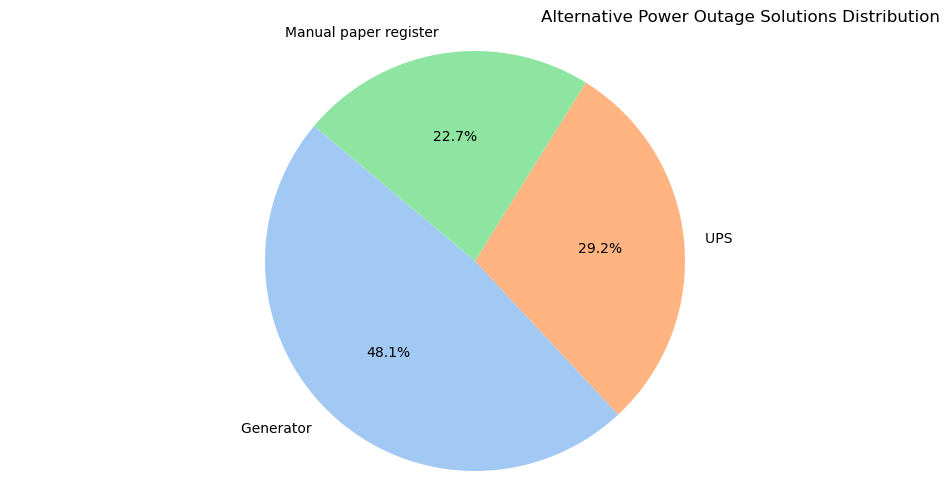

In [60]:
plt.figure(figsize=(12, 6))
plt.pie(df['alternative_power_outage'].value_counts(), labels=df['alternative_power_outage'].value_counts().index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Alternative Power Outage Solutions Distribution', loc='right')
plt.axis('equal')
plt.show()

### Equipment availability 

In [61]:
df['emr_designated_computer'].value_counts()

emr_designated_computer
1    152
0      2
Name: count, dtype: int64

In [62]:
emr_designated_mapping = {
    1: 'Yes',
    0: 'No',
    }
df['emr_designated_computer'] = df['emr_designated_computer'].replace(emr_designated_mapping)
df['emr_designated_computer'].value_counts()

emr_designated_computer
Yes    152
No       2
Name: count, dtype: int64

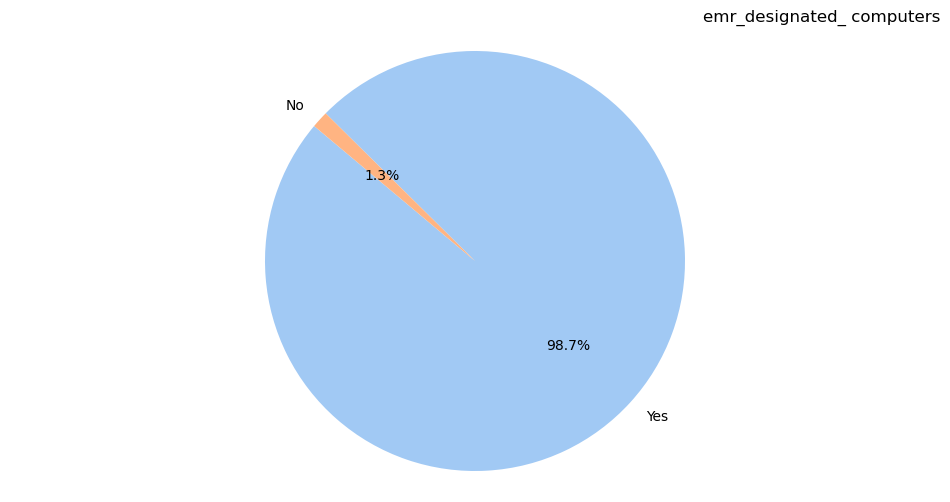

In [63]:
plt.figure(figsize=(12, 6))
plt.pie(df['emr_designated_computer'].value_counts(), labels=df['emr_designated_computer'].value_counts().index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('emr_designated_ computers', loc='right')
plt.axis('equal')
plt.show()

### System deployment modes

In [64]:
df['emr_online_offline'].value_counts()

emr_online_offline
2    126
1     28
Name: count, dtype: int64

In [65]:
emr_online_offline_mapping = {
    2: 'Online',
    1: 'Offline',
    }
df['emr_online_offline'] = df['emr_online_offline'].replace(emr_online_offline_mapping)
df['emr_online_offline'].value_counts()

emr_online_offline
Online     126
Offline     28
Name: count, dtype: int64

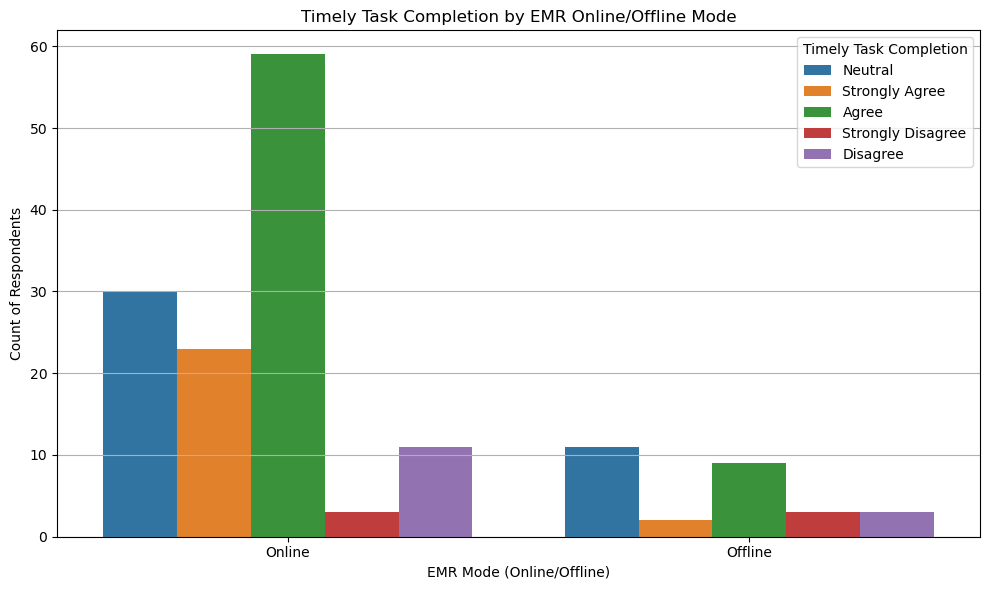

In [66]:
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df,
    x='emr_online_offline',
    hue='timely_completion_emr_tasks',
)

# Add clear labels and a title
plt.title('Timely Task Completion by EMR Online/Offline Mode')
plt.xlabel('EMR Mode (Online/Offline)')
plt.ylabel('Count of Respondents')
plt.xticks(rotation=0)
plt.legend(title='Timely Task Completion')
plt.grid(axis='y')
# Adjust layout and show the plot
plt.tight_layout()
plt.show()

## Technical Support System Evaluation

### technical_support_time

In [67]:
df['technical_support_time'].value_counts()

technical_support_time
Within 24 hours     142
1-7 days             11
14 days+              1
Name: count, dtype: int64

In [68]:
df['technical_support_time'].unique()

array(['Within 24 hours ', '1-7 days ', '14 days+'], dtype=object)

/var/folders/rr/bq788s793lj_d9_kkdn7gqrr0000gn/T/ipykernel_3583/3562276447.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


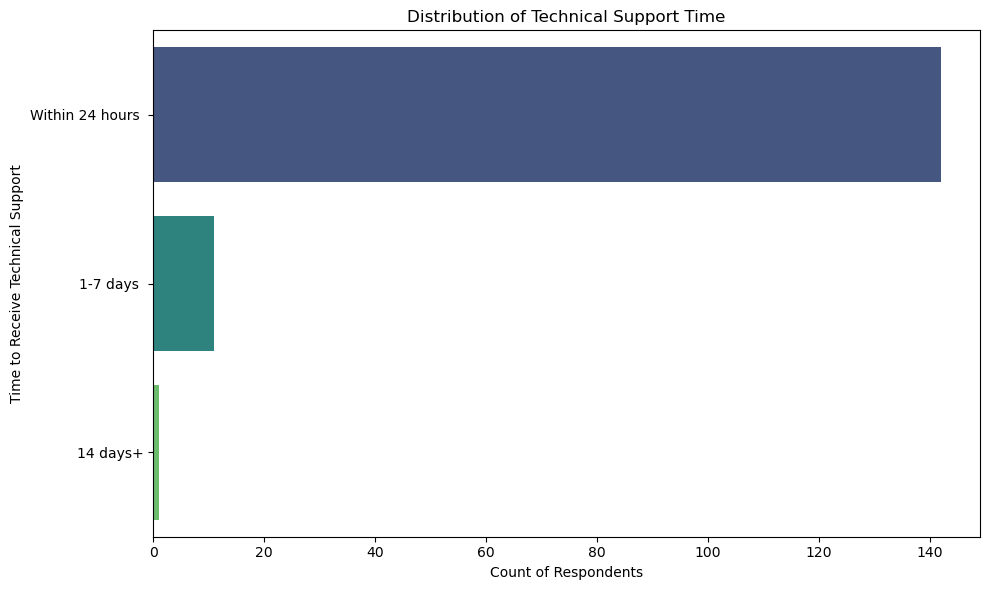

In [69]:
time_order = ['Within 24 hours ', '1-7 days ', '14 days+']

# Create the bar chart using seaborn's catplot for better ordering control
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df,
    y='technical_support_time', # Use 'y' for horizontal bars
    order=time_order,
    palette='viridis' # A cool-looking color palette
)

# Add clear labels and a title
plt.title('Distribution of Technical Support Time')
plt.ylabel('Time to Receive Technical Support')
plt.xlabel('Count of Respondents')
plt.tight_layout()
plt.show()

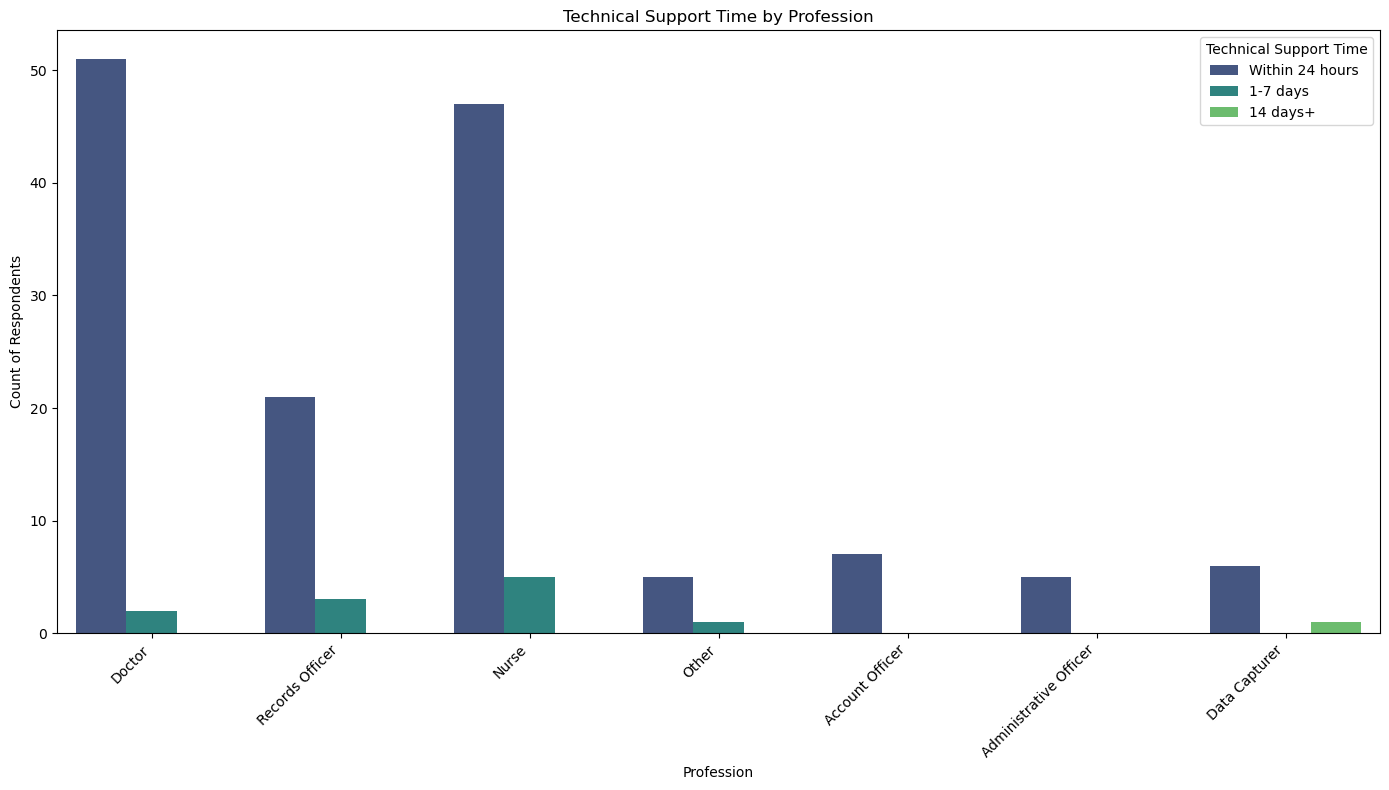

In [70]:
plt.figure(figsize=(14, 8))
sns.countplot(
    data=df,
    x='profession',
    hue='technical_support_time',
    hue_order=time_order,
    palette='viridis'
)

# Add labels and a title
plt.title('Technical Support Time by Profession')
plt.xlabel('Profession')
plt.ylabel('Count of Respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Technical Support Time')
plt.tight_layout()
plt.show()

### need_technical_support

In [71]:
df['need_technical_support'].value_counts()

need_technical_support
2    57
1    51
4    23
3    16
5     7
Name: count, dtype: int64

In [72]:
technial_support_mapping = {
    1: 'Strongly Disagree',
    2: 'Disagree',
    3: 'Neutral',
    4: 'Agree',
    5: 'Strongly Agree',
}
df['need_technical_support'] = df['need_technical_support'].replace(technial_support_mapping)
df['need_technical_support'].value_counts()

need_technical_support
Disagree             57
Strongly Disagree    51
Agree                23
Neutral              16
Strongly Agree        7
Name: count, dtype: int64

/var/folders/rr/bq788s793lj_d9_kkdn7gqrr0000gn/T/ipykernel_3583/3014370532.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='need_technical_support', data=df, order=df['need_technical_support'].value_counts().index, palette='viridis')


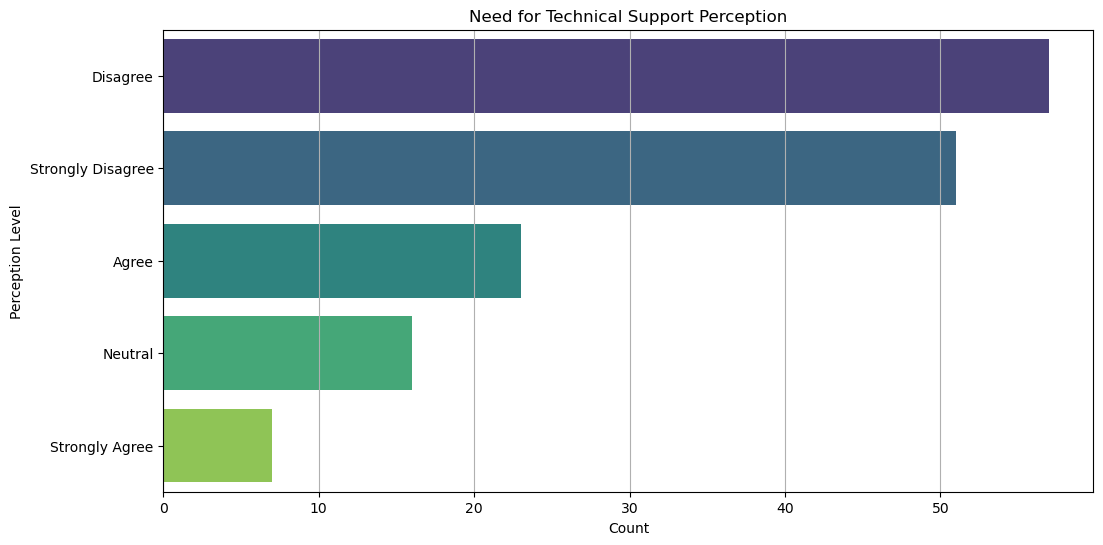

In [73]:
plt.figure(figsize=(12, 6))
sns.countplot(y='need_technical_support', data=df, order=df['need_technical_support'].value_counts().index, palette='viridis')
plt.title('Need for Technical Support Perception')
plt.xlabel('Count')
plt.ylabel('Perception Level')
plt.grid(axis='x')
plt.show()


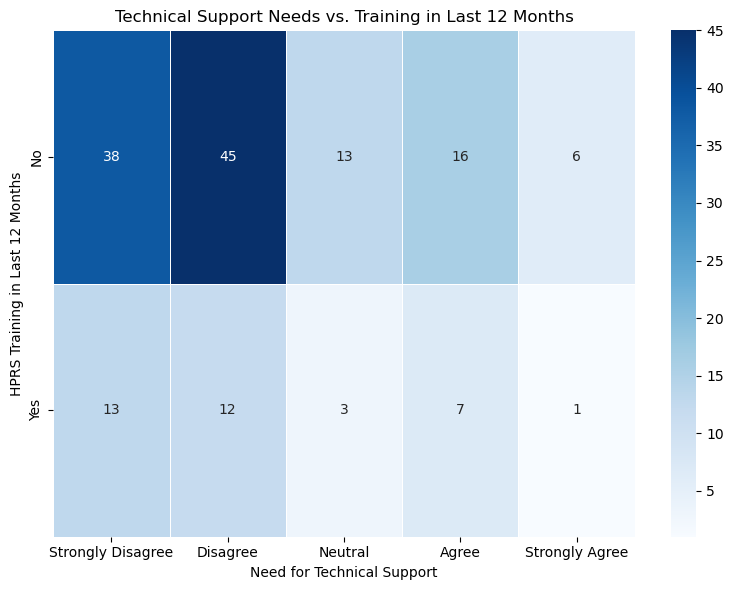

In [74]:
cross_tab = pd.crosstab(df['hprs_training_last_12_months'], df['need_technical_support'])
column_order = ['Strongly Disagree', 'Disagree', 'Neutral', 'Agree', 'Strongly Agree']
cross_tab = cross_tab[column_order]
# Create the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    cross_tab,
    annot=True,     # Annotate the cells with the count
    fmt='d',        # Format the annotations as integers
    cmap='Blues',   # A nice color map
    linewidths=.5,  # Add lines to separate the cells
    cbar=True       # Display the color bar
)

# Add labels and a title
plt.title('Technical Support Needs vs. Training in Last 12 Months')
plt.xlabel('Need for Technical Support')
plt.ylabel('HPRS Training in Last 12 Months')
plt.tight_layout()
plt.show()

### database_version

In [75]:
df['db_version'].value_counts()

db_version
Other                 61
Unknown               58
Global Care V.10.1    26
EMR                    9
Name: count, dtype: int64

In [76]:
df['confidence_using_system'].value_counts()

confidence_using_system
4    72
5    52
3    12
1    10
2     8
Name: count, dtype: int64

In [77]:
df['confidence_using_system'].unique()

array([4, 1, 5, 2, 3])

In [78]:
confidence_mapping = {
    1: 'Strongly Disagree',
    2: 'Disagree',
    3: 'Neutral',
    4: 'Agree',
    5: 'Strongly Agree',
}
df['confidence_using_system'] = df['confidence_using_system'].replace(confidence_mapping)
df['confidence_using_system'].value_counts()

confidence_using_system
Agree                72
Strongly Agree       52
Neutral              12
Strongly Disagree    10
Disagree              8
Name: count, dtype: int64

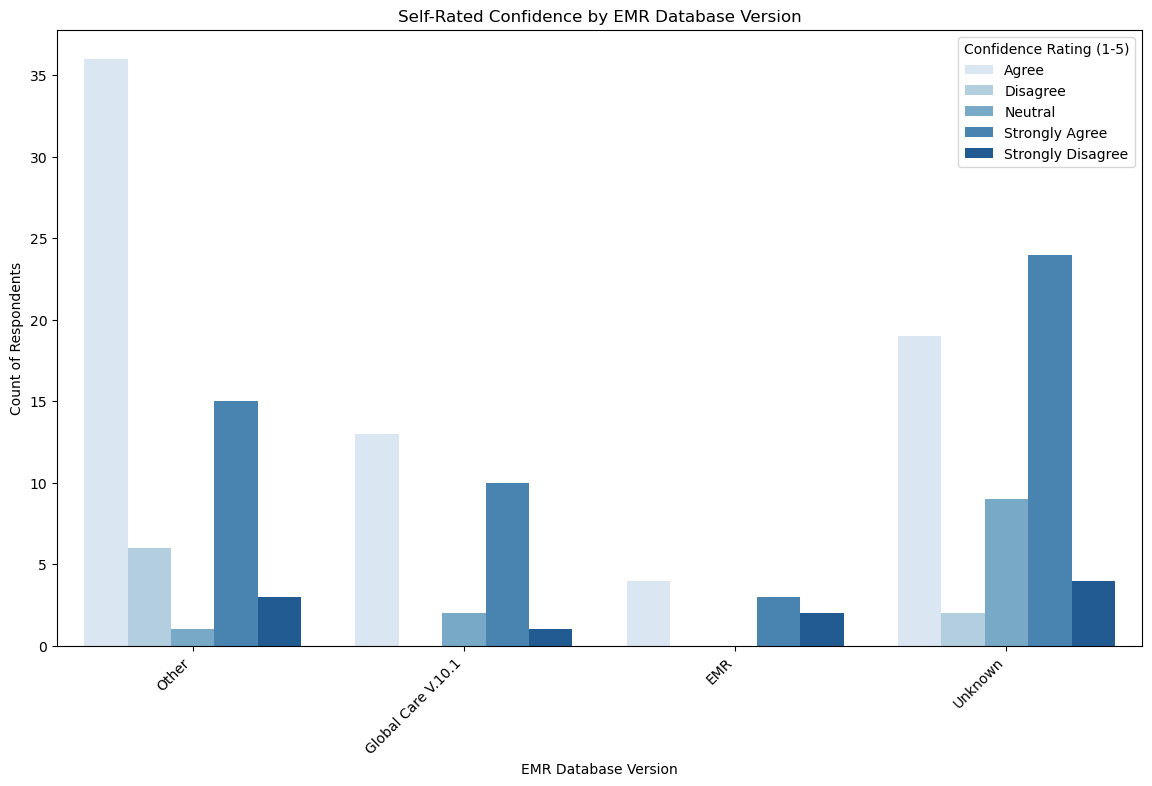

In [79]:
confidence_order = sorted(df['confidence_using_system'].unique())

# Create the grouped bar chart
plt.figure(figsize=(14, 8))
sns.countplot(
    data=df,
    x='db_version',
    hue='confidence_using_system',
    hue_order=confidence_order,
    palette='Blues'
)

# Add clear labels and a title
plt.title('Self-Rated Confidence by EMR Database Version')
plt.xlabel('EMR Database Version')
plt.ylabel('Count of Respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Confidence Rating (1-5)')
#plt.tight_layout()
plt.show()

# Organizational/Environmental Components Analysis

## Leadership & Management Support

### poor leadership

In [80]:
df['org_factor_poor_leadership'].value_counts()

org_factor_poor_leadership
0    140
1     14
Name: count, dtype: int64

In [81]:
org_factor_mapping = {
    0: 'No',
    1: 'Yes'
}
df['org_factor_poor_leadership'] = df['org_factor_poor_leadership'].replace(org_factor_mapping)
df['org_factor_poor_leadership'].value_counts()

org_factor_poor_leadership
No     140
Yes     14
Name: count, dtype: int64

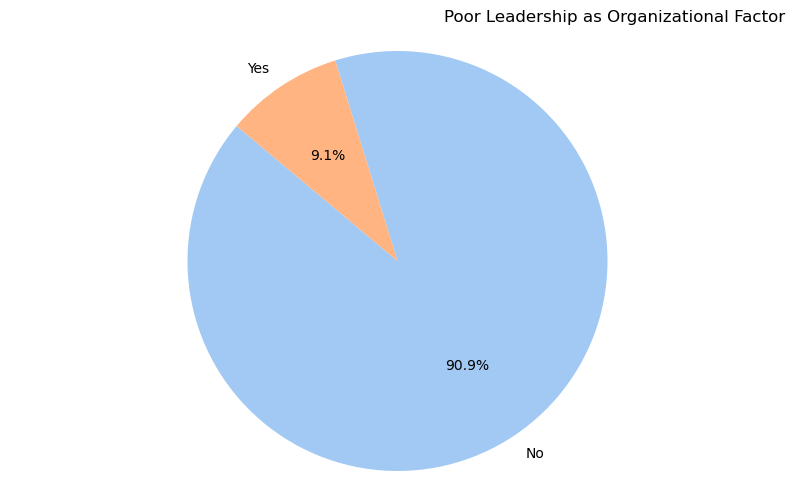

In [82]:
plt.figure(figsize=(10, 6))
plt.pie(df['org_factor_poor_leadership'].value_counts(), labels=df['org_factor_poor_leadership'].value_counts().index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Poor Leadership as Organizational Factor', loc='right')
plt.axis('equal')
plt.show()

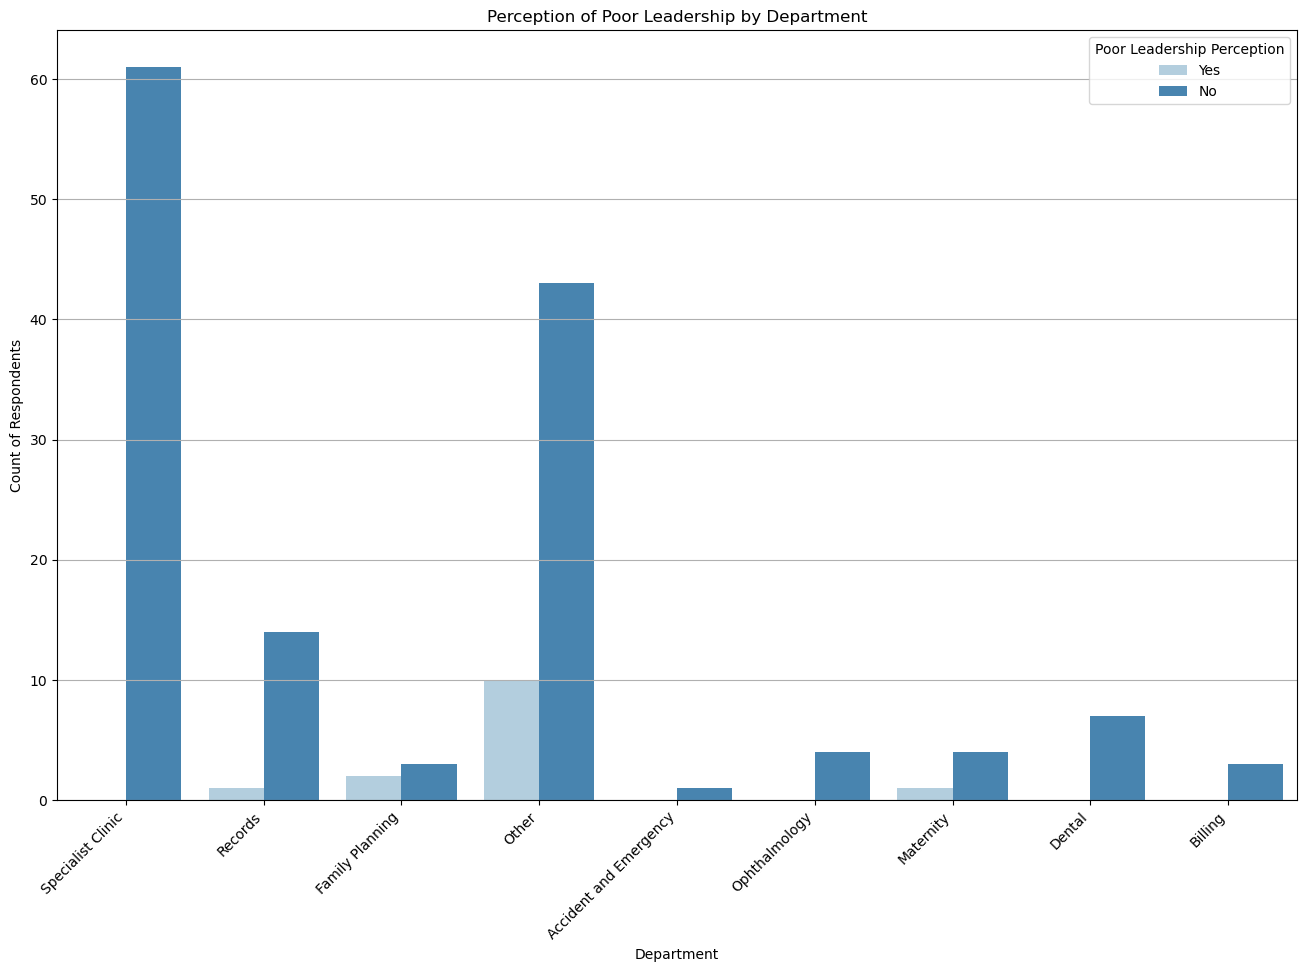

In [83]:
leadership_order = ['Yes', 'No']

# Create the grouped bar chart
plt.figure(figsize=(16, 10))
sns.countplot(
    data=df,
    x='department',
    hue='org_factor_poor_leadership',
    hue_order=leadership_order,
    palette='Blues'
)

# Add labels and a title
plt.title('Perception of Poor Leadership by Department')
plt.xlabel('Department')
plt.ylabel('Count of Respondents')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y')
plt.legend(title='Poor Leadership Perception')
plt.show()

### capacity decision making


In [84]:
df['capacity_decision_making'].value_counts()

capacity_decision_making
1    119
0     35
Name: count, dtype: int64

In [85]:
capacity_mapping = {
    0: 'No',
    1: 'Yes'
}
df['capacity_decision_making'] = df['capacity_decision_making'].replace(capacity_mapping)
df['capacity_decision_making'].value_counts()

capacity_decision_making
Yes    119
No      35
Name: count, dtype: int64

In [86]:
likely_to_use_mapping = {
    1: 'Strongly Disagree',
    2: 'Disagree',
    3: 'Neutral',
    4: 'Agree',
    5: 'Strongly Agree',
}
df['likely_to_use_emr'] = df['likely_to_use_emr'].replace(likely_to_use_mapping)
df['likely_to_use_emr'].value_counts()

likely_to_use_emr
Strongly Agree       81
Agree                43
Strongly Disagree    17
Neutral               9
Disagree              4
Name: count, dtype: int64

In [87]:
df['likely_to_use_emr'].unique()

array(['Agree', 'Strongly Disagree', 'Strongly Agree', 'Neutral',
       'Disagree'], dtype=object)

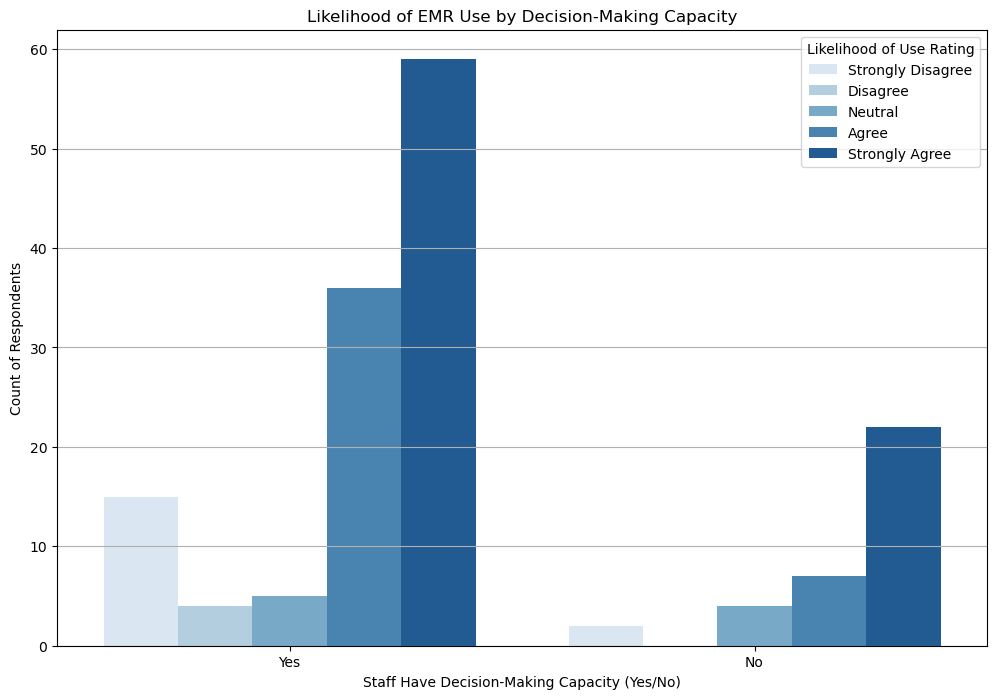

In [88]:
likelihood_order =  column_order

# Create the grouped bar chart
plt.figure(figsize=(12, 8))
sns.countplot(
    data=df,
    x='capacity_decision_making',
    hue='likely_to_use_emr',
    hue_order=likelihood_order,
    palette='Blues'
)

# Add labels and a title
plt.title('Likelihood of EMR Use by Decision-Making Capacity')
plt.xlabel('Staff Have Decision-Making Capacity (Yes/No)')
plt.ylabel('Count of Respondents')
plt.xticks(rotation=0)
plt.legend(title='Likelihood of Use Rating')
plt.grid(axis='y')
plt.show()

### regular_monitoring_evaluation_supervisor

In [89]:
df['regular_monitoring_evaluation_supervision'].value_counts()

regular_monitoring_evaluation_supervision
1    128
0     26
Name: count, dtype: int64

In [90]:
regular_monitoring_mapping = {
    0: 'No',
    1: 'Yes'
}
df['regular_monitoring_evaluation_supervision'] = df['regular_monitoring_evaluation_supervision'].replace(regular_monitoring_mapping)
df['regular_monitoring_evaluation_supervision'].value_counts()

regular_monitoring_evaluation_supervision
Yes    128
No      26
Name: count, dtype: int64

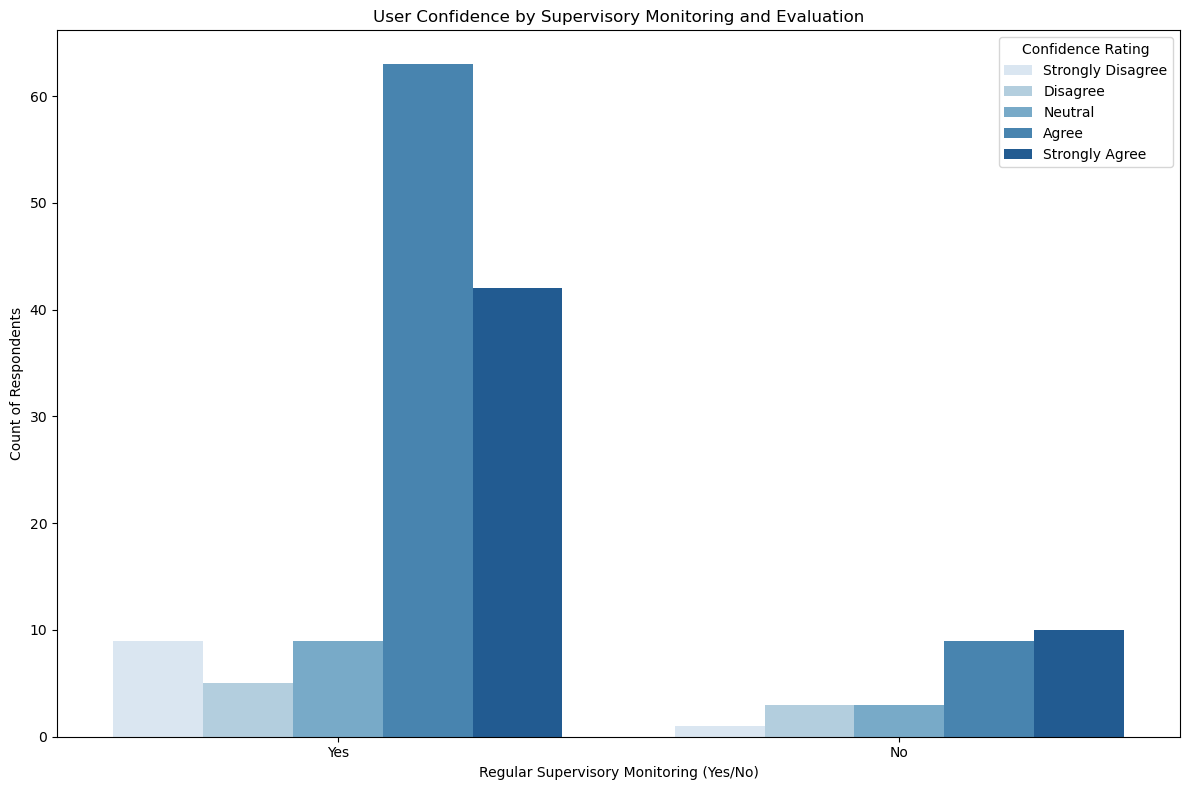

In [91]:
confidence_order = column_order

# Create the grouped bar chart
plt.figure(figsize=(12, 8))
sns.countplot(
    data=df,
    x='regular_monitoring_evaluation_supervision',
    hue='confidence_using_system',
    hue_order=confidence_order,
    palette='Blues'
)

# Add labels and a title
plt.title('User Confidence by Supervisory Monitoring and Evaluation')
plt.xlabel('Regular Supervisory Monitoring (Yes/No)')
plt.ylabel('Count of Respondents')
plt.xticks(rotation=0)
plt.legend(title='Confidence Rating')
plt.tight_layout()
plt.show()

### organizational practices

In [92]:
df['org_factor_organizational_practices'].value_counts()

org_factor_organizational_practices
1    100
0     54
Name: count, dtype: int64

In [93]:
df['org_factor_organizational_practices'] = df['org_factor_organizational_practices'].replace(org_factor_mapping)
df['org_factor_organizational_practices'].value_counts()

org_factor_organizational_practices
Yes    100
No      54
Name: count, dtype: int64

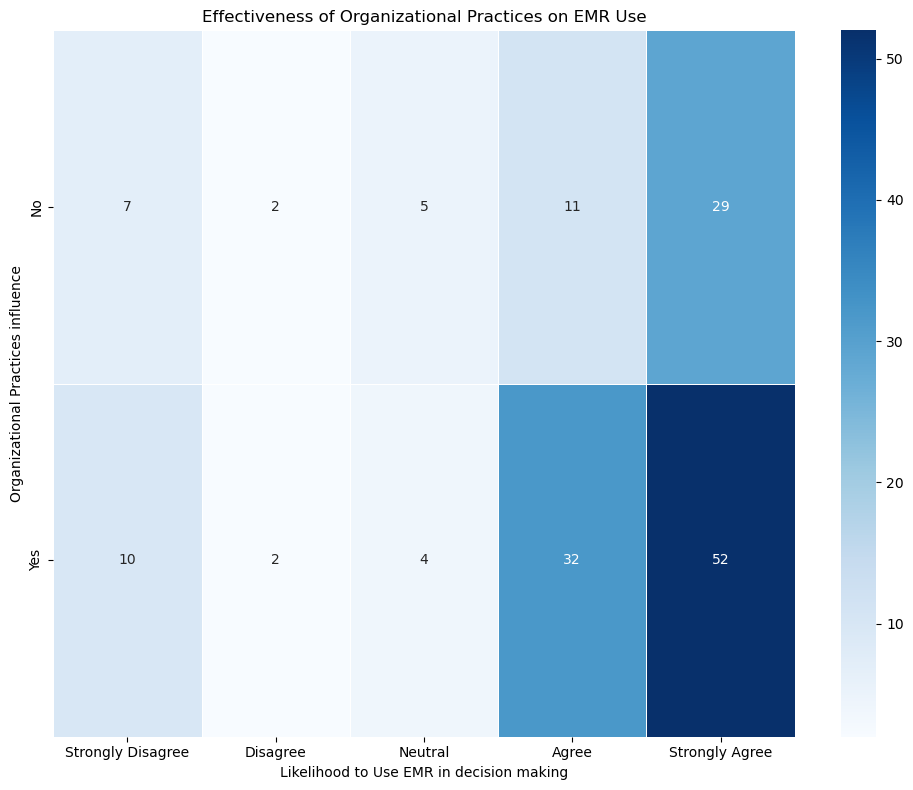

In [94]:
cross_tab = pd.crosstab(df['org_factor_organizational_practices'], df['likely_to_use_emr'])
cross_tab = cross_tab[column_order]
# Create the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    cross_tab,
    annot=True,     # Annotate the cells with the count
    fmt='d',        # Format the annotations as integers
    cmap='Blues',   # Use the consistent blue color theme
    linewidths=.5,  # Add lines to separate the cells
    cbar=True       # Display the color bar
)

# Add labels and a title
plt.title('Effectiveness of Organizational Practices on EMR Use')
plt.xlabel('Likelihood to Use EMR in decision making')
plt.ylabel('Organizational Practices influence')
plt.tight_layout()
plt.show()

In [95]:
df['health_information_policies'].value_counts() # well streamlined health information policies

health_information_policies
1    130
0     24
Name: count, dtype: int64

In [96]:
df['health_information_policies'] = df['health_information_policies'].replace(org_factor_mapping)
df['health_information_policies'].value_counts()

health_information_policies
Yes    130
No      24
Name: count, dtype: int64

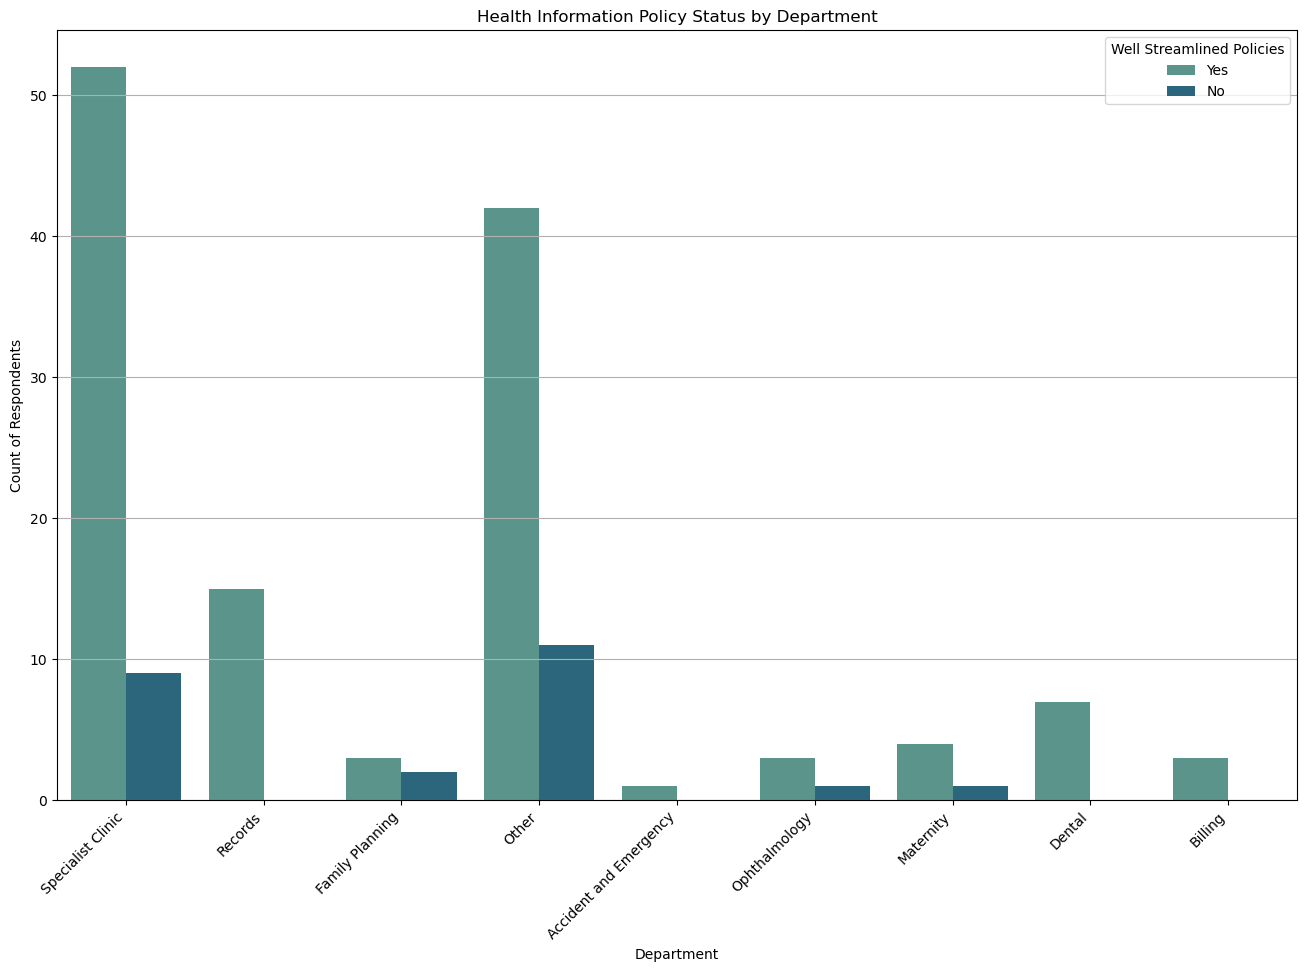

In [97]:
policy_order = ['Yes', 'No']

# Create the grouped bar chart
plt.figure(figsize=(16, 10))
sns.countplot(
    data=df,
    x='department',
    hue='health_information_policies',
    hue_order=policy_order,
    palette='crest'
)

# Add clear labels and a title
plt.title('Health Information Policy Status by Department')
plt.xlabel('Department')
plt.ylabel('Count of Respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Well Streamlined Policies')
#plt.tight_layout()
plt.grid(axis='y')
plt.show()

In [98]:
df['action_plan_emr'].value_counts() # existence of action plan for emr implementation

action_plan_emr
1    131
0     23
Name: count, dtype: int64

In [99]:
df['action_plan_emr'] = df['action_plan_emr'].replace(org_factor_mapping)
df['action_plan_emr'].value_counts()

action_plan_emr
Yes    131
No      23
Name: count, dtype: int64

In [100]:

# Assuming your DataFrame is named 'df'
# Create a cross-tabulation table with percentages
cross_tab_pct = pd.crosstab(
    df['action_plan_emr'],
    df['likely_to_use_emr'],
    normalize='index'  # Normalize across rows to get percentages
) * 100 # Multiply by 100 to make it a percentage

# Print the table, rounded to 2 decimal places
print("Percentage Distribution of Likelihood to Use EMR by Action Plan Presence:")
print(round(cross_tab_pct, 2))

Percentage Distribution of Likelihood to Use EMR by Action Plan Presence:
likely_to_use_emr  Agree  Disagree  Neutral  Strongly Agree  Strongly Disagree
action_plan_emr                                                               
No                 30.43      0.00    17.39           47.83               4.35
Yes                27.48      3.05     3.82           53.44              12.21


<Figure size 1000x600 with 0 Axes>

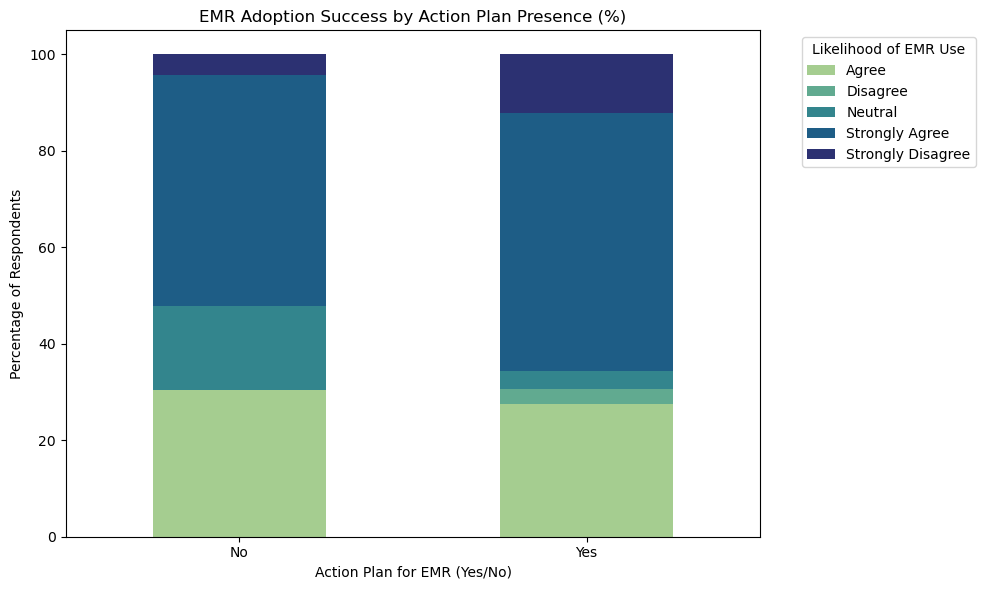

In [101]:
likelihood_order = sorted(cross_tab_pct.columns)
cross_tab_pct_ordered = cross_tab_pct[likelihood_order]

# Plot the stacked bar chart
plt.figure(figsize=(10, 6))
cross_tab_pct_ordered.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap='crest'  # Use a blue color palette
)

# Add labels and a title
plt.title('EMR Adoption Success by Action Plan Presence (%)')
plt.xlabel('Action Plan for EMR (Yes/No)')
plt.ylabel('Percentage of Respondents')
plt.xticks(rotation=0)
plt.legend(title='Likelihood of EMR Use', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [102]:
df['org_factor_financial_resources'].value_counts() # availability of financial resources

org_factor_financial_resources
1    79
0    75
Name: count, dtype: int64

In [103]:
df['og']

KeyError: 'og'